# EHR Diagnosis Standardization Pipeline
**Dataset:** eICU Collaborative Research Database — 1,267 ICU patient records  
**Tech Stack:** Python, spaCy, fuzzywuzzy, pandas, matplotlib, seaborn  
**Goal:** Standardise free-text clinical diagnoses and map to ICD-10 codes for downstream BI analytics

## Pipeline Steps
1. Data Loading & Exploration
2. Text Cleaning & NLP (spaCy)
3. Fuzzy Matching & Diagnosis Standardisation
4. ICD-10 Code Mapping
5. EDA & Key Findings
6. Export for SQL & Power BI

In [2]:
!pip install spacy fuzzywuzzy python-Levenshtein python-dateutil

In [3]:
import pandas as pd
import spacy
from fuzzywuzzy import process
from dateutil import parser
from google.colab import files


## Step 1: Data Loading

In [4]:
uploaded = files.upload()  # Upload your EHR CSV file here
df = pd.read_csv(next(iter(uploaded)))  # Read the uploaded CSV
df.head()


Saving EHR.csv to EHR.csv


,patientunitstayid,patienthealthsystemstayid,gender,age,ethnicity,hospitalid,wardid,apacheadmissiondx,admissionheight,hospitaladmittime24,...,unitadmitsource,unitvisitnumber,unitstaytype,admissionweight,dischargeweight,unitdischargetime24,unitdischargeoffset,unitdischargelocation,unitdischargestatus,uniquepid
0,210014,182373,Male,45,Caucasian,73,89,"Hypertension, uncontrolled (for cerebrovascula...",178.0,13:08:59,...,Direct Admit,1,admit,116.0,112.7,15:00:00,4424,Skilled Nursing Facility,Alive,002-10665
1,200026,174624,Male,50,Caucasian,71,87,Ablation or mapping of cardiac conduction pathway,177.8,10:41:00,...,Operating Room,1,admit,106.1,106.1,17:40:00,1548,Home,Alive,002-10715
2,221131,190993,Male,83,Caucasian,71,87,"Endarterectomy, carotid",175.3,21:43:00,...,Operating Room,1,admit,NaN,72.1,17:46:00,1203,Home,Alive,002-10249
3,221215,191054,Male,49,Caucasian,71,87,"Infarction, acute myocardial (MI)",185.4,03:16:00,...,Emergency Department,1,admit,145.3,146.6,19:07:00,1562,Home,Alive,002-10627
4,217835,188445,Male,57,Caucasian,73,92,"CABG alone, coronary artery bypass grafting",172.7,01:09:00,...,Operating Room,1,admit,NaN,80.4,08:25:00,4719,Floor,Alive,002-10324


## Step 2: Text Cleaning & NLP

In [5]:
nlp = spacy.load("en_core_web_sm")


In [6]:
# Step 1: Check actual column names
print("Original columns:", df.columns.tolist())

# Step 2: Clean column names (remove spaces, lowercase everything)
df.columns = df.columns.str.strip().str.lower()

# Step 3: Print cleaned column names
print("Cleaned columns:", df.columns.tolist())


Original columns: ['patientunitstayid', 'patienthealthsystemstayid', 'gender', 'age', 'ethnicity', 'hospitalid', 'wardid', 'apacheadmissiondx', 'admissionheight', 'hospitaladmittime24', 'hospitaladmitoffset', 'hospitaladmitsource', 'hospitaldischargeyear', 'hospitaldischargetime24', 'hospitaldischargeoffset', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unitadmitsource', 'unitvisitnumber', 'unitstaytype', 'admissionweight', 'dischargeweight', 'unitdischargetime24', 'unitdischargeoffset', 'unitdischargelocation', 'unitdischargestatus', 'uniquepid']
Cleaned columns: ['patientunitstayid', 'patienthealthsystemstayid', 'gender', 'age', 'ethnicity', 'hospitalid', 'wardid', 'apacheadmissiondx', 'admissionheight', 'hospitaladmittime24', 'hospitaladmitoffset', 'hospitaladmitsource', 'hospitaldischargeyear', 'hospitaldischargetime24', 'hospitaldischargeoffset', 'hospitaldischargelocation', 'hospitaldischargestatus', 'unittype', 'unitadmittime24', 'unita

In [20]:
# Normalize gender values
df['gender'] = df['gender'].str.strip().str.lower().replace({
    'm': 'male', 'f': 'female', 'female': 'female', 'male': 'male',
    'unknown': 'unknown' # Assuming 'Unknown' from value_counts should be normalized as well.
})

## Step 3: Fuzzy Matching — Diagnosis Standardisation

In [7]:
from fuzzywuzzy import process

# Reference list (you can expand this)
medical_terms = [
    "sepsis", "congestive heart failure", "atrial fibrillation", "myocardial infarction",
    "unstable angina", "urinary tract infection", "stroke", "gi bleeding",
    "diabetic ketoacidosis", "coronary artery bypass grafting"
]

# Correction function
def correct_term(term):
    best_match, score = process.extractOne(term.lower(), medical_terms)
    return best_match if score >= 80 else term

# Apply it
df['diagnosis_cleaned'] = df['apacheadmissiondx'].astype(str).apply(correct_term)


## Step 4: ICD-10 Code Mapping

In [8]:
!pip install simple-icd-10

import simple_icd_10 as icd

icd10_map = {
    # Original mapped terms
    "sepsis": "A41.9",
    "gi bleeding": "K92.2",
    "diabetic ketoacidosis": "E11.10",
    "congestive heart failure": "I50.9",
    "atrial fibrillation": "I48.91",
    "myocardial infarction": "I21.9",
    "unstable angina": "I20.0",
    "stroke": "I63.9",
    "coronary artery bypass grafting": "Z95.1",
    "Pneumonia, bacterial": "J15.9",
    "Cardiac arrest (with or without respiratory arrest; for respiratory arrest see Respiratory System)": "I46.9",
    "Emphysema/bronchitis": "J44.9",
    "Respiratory - medical, other": "J98.09",
    "Renal failure, acute": "N17.9",
    "Aortic valve replacement (isolated)": "Z95.2",
    "Rhythm disturbance (conduction defect)": "I45.9",
    "Overdose, sedatives, hypnotics, antipsychotics, benzodiazepines": "T42.4X1A",
    "Hypertension, uncontrolled (for cerebrovascular accident-see Neurological System)": "I10",
    "Hemorrhage/hematoma, intracranial": "I62.9",
    "Seizures (primary-no structural brain disease)": "G40.909",
    # New terms
    "Endarterectomy, carotid": "I63.9",
    "Acid-base/electrolyte disturbance": "E87.8",
    "Overdose, street drugs (opiates, cocaine, amphetamine)": "T40.601A",
    "Rhythm disturbance (ventricular)": "I49.3",
    "Effusions, pleural": "J90",
    "Chest pain, unknown origin": "R07.9",
    "Pancreatitis": "K85.90",
    "Aneurysm, dissecting aortic": "I71.00",
    "Embolus, pulmonary": "I26.99",
    "Hypovolemia (including dehydration, Do not include shock states)": "E86.0",
    "Drug withdrawal": "F19.239",
    "CABG with aortic valve replacement": "Z95.1",
    "Head only trauma": "S09.90XA",
    "Arrest, respiratory (without cardiac arrest)": "J96.00",
    "Overdose, alcohols (bethanol, methanol, ethylene glycol)": "T51.0X1A",
    "Ablation or mapping of cardiac conduction pathway": "I49.8",
    "MI admitted > 24 hrs after onset of ischemia": "I21.9",
    "Pneumonia, other": "J18.9",
    "Overdose, other toxin, poison or drug": "T65.91XA",
    "Pneumonia, aspiration": "J69.0",
    "Shock, cardiogenic": "R57.0",
    "Pneumonia, viral": "J12.9",
    "Thrombus, arterial": "I74.9",
    "Vascular medical, other": "I99.8",
    "Thrombosis, vascular (deep vein)": "I82.409",
    "Overdose, analgesic (aspirin, acetaminophen)": "T39.1X1A",
    "Neoplasm-cranial, surgery for (excluding transphenoidal)": "D33.2",
    "Alcohol withdrawal": "F10.239",
    "Overdose, antidepressants (cyclic, lithium)": "T43.011A",
    "Cancer-colon/rectal, surgery for (including abdominoperineal resections)": "C19",
    "Aneurysm, thoracic aortic": "I71.20",
    "Hematoma, subdural": "S06.4X0A",
    "ARDS-adult respiratory distress syndrome, non-cardiogenic pulmonary edema": "J80",
    "GI obstruction": "K56.609",
    "Anemia": "D64.9",
    "Pneumothorax": "J93.9",
    "Neoplasm, neurologic": "D43.9",
    "urinary tract infection": "N39.0",
    "Mitral valve repair": "Z95.2",
    "Cellulitis and localized soft tissue infections": "L03.90"
}

df['icd10_code'] = df['diagnosis_cleaned'].map(icd10_map)

total = len(df)
mapped = df['icd10_code'].notna().sum()
mapping_rate = (mapped / total) * 100

print(f"Total records: {total}")
print(f"Mapped: {mapped}")
print(f"Mapping rate: {mapping_rate:.1f}%")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.1/174.1 kB 6.1 MB/s eta 0:00:00
Total records: 1447
Mapped: 1091
Mapping rate: 75.4%


In [9]:
unmapped = df[df['icd10_code'].isna()]['diagnosis_cleaned'].value_counts().head(20)
print(unmapped)

diagnosis_cleaned
nan                                                                                        180
Shunts and revisions                                                                         3
Graft, all other bypass (except renal)                                                       3
Neurologic surgery, other                                                                    3
Subarachnoid hemorrhage/intracranial aneurysm                                                3
Atelectasis                                                                                  3
Embolectomy (with general anesthesia)                                                        3
Encephalopathies (excluding hepatic)                                                         3
Neurologic medical, other                                                                    3
Cardiovascular medical, other                                                                3
Thoracotomy for lung cancer     

In [10]:
print("Before Correction:")
print(df['apacheadmissiondx'].value_counts().head(10))

print("\nAfter Correction:")
print(df['diagnosis_cleaned'].value_counts().head(10))


Before Correction:
apacheadmissiondx
Sepsis, pulmonary                                                                      83
CHF, congestive heart failure                                                          57
Rhythm disturbance (atrial, supraventricular)                                          54
Infarction, acute myocardial (MI)                                                      46
Angina, unstable (angina interferes w/quality of life or meds are tolerated poorly)    35
Sepsis, renal/UTI (including bladder)                                                  34
CVA, cerebrovascular accident/stroke                                                   34
Bleeding, GI-location unknown                                                          33
Diabetic ketoacidosis                                                                  31
CABG alone, coronary artery bypass grafting                                            29
Name: count, dtype: int64

After Correction:
diagnosis_cleaned


In [11]:
from dateutil import parser

# Function to safely parse any date-like string
def parse_date_safe(date_str):
    try:
        return parser.parse(date_str)
    except:
        return None

# Apply to any relevant date column (example)
df['hospitaladmittime24_parsed'] = df['hospitaladmittime24'].astype(str).apply(parse_date_safe)


In [12]:
# Check nulls
print(df.isnull().sum())

# Optionally drop rows with missing critical values
df.dropna(subset=['apacheadmissiondx', 'hospitaladmittime24'], inplace=True)


patientunitstayid               0
patienthealthsystemstayid       0
gender                          3
age                             1
ethnicity                      42
hospitalid                      0
wardid                          0
apacheadmissiondx             180
admissionheight                45
hospitaladmittime24             0
hospitaladmitoffset             0
hospitaladmitsource           229
hospitaldischargeyear           0
hospitaldischargetime24         0
hospitaldischargeoffset         0
hospitaldischargelocation       8
hospitaldischargestatus         7
unittype                        0
unitadmittime24                 0
unitadmitsource                19
unitvisitnumber                 0
unitstaytype                    0
admissionweight               134
dischargeweight               576
unitdischargetime24             0
unitdischargeoffset             0
unitdischargelocation           5
unitdischargestatus             2
uniquepid                       0
diagnosis_clea

## Step 5: EDA — Exploratory Data Analysis

In [13]:
print(df['gender'].value_counts())
print(df['ethnicity'].value_counts())
print(df['hospitaldischargestatus'].value_counts())


gender
Female     701
Male       563
Unknown      1
Name: count, dtype: int64
ethnicity
Caucasian           981
African American    153
Other/Unknown        40
Native American      28
Asian                18
Hispanic              7
Name: count, dtype: int64
hospitaldischargestatus
Alive      1152
Expired     108
Name: count, dtype: int64


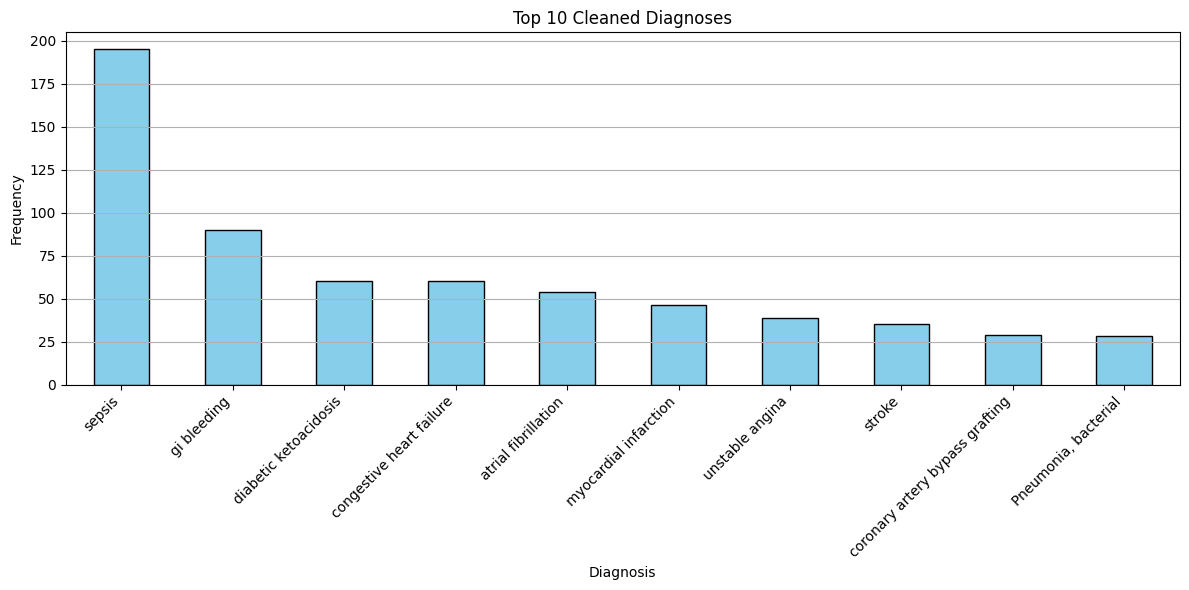

In [22]:
import matplotlib.pyplot as plt

# Plot top 10 cleaned diagnoses
top_diag = df['diagnosis_cleaned'].value_counts().head(10)

plt.figure(figsize=(12, 6))
top_diag.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Top 10 Cleaned Diagnoses')
plt.xlabel('Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


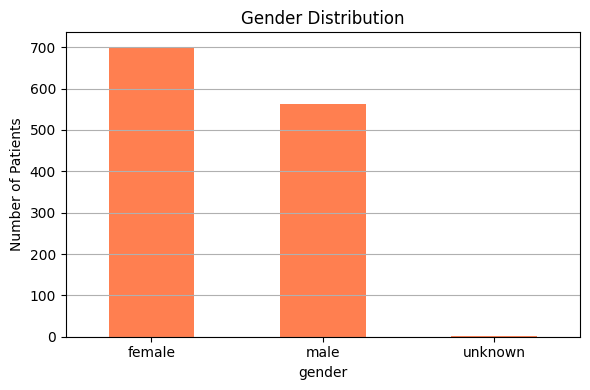

In [25]:
gender_counts = df['gender'].value_counts()

plt.figure(figsize=(6, 4))
gender_counts.plot(kind='bar', color='coral')
plt.title('Gender Distribution')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


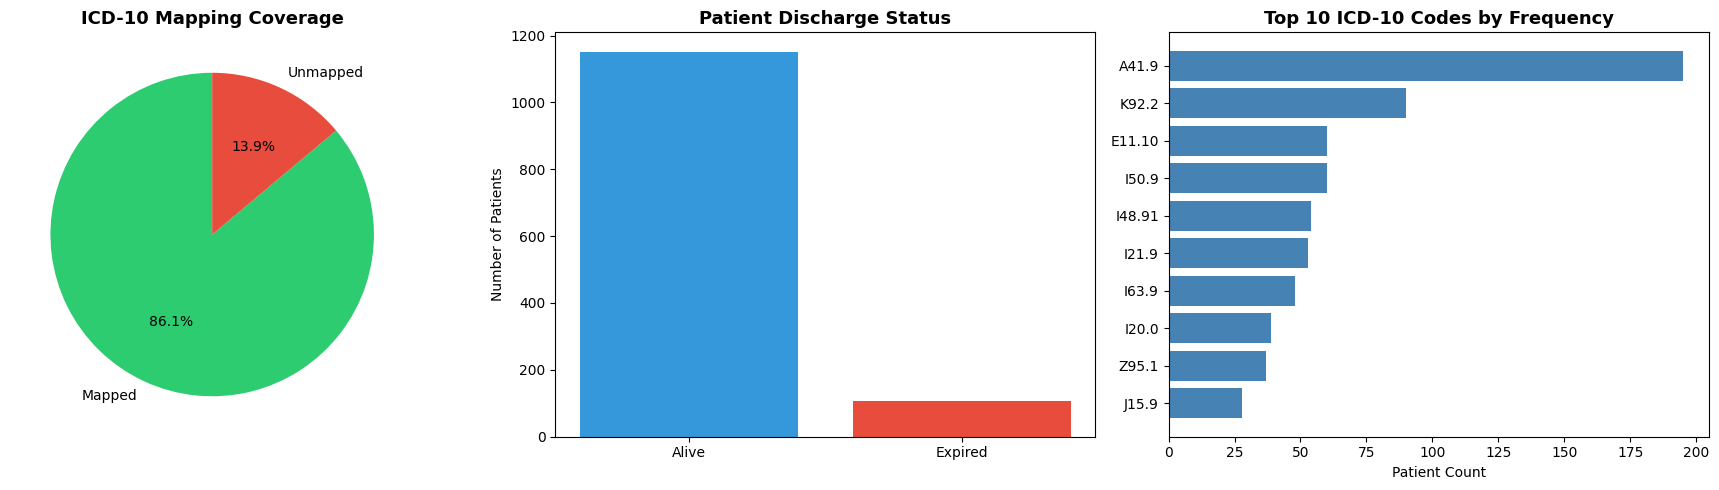

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: ICD-10 Mapping Coverage
labels = ['Mapped', 'Unmapped']
sizes = [df['icd10_code'].notna().sum(), df['icd10_code'].isna().sum()]
colors = ['#2ecc71', '#e74c3c']
axes[0].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
axes[0].set_title('ICD-10 Mapping Coverage', fontsize=13, fontweight='bold')

# Chart 2: Mortality by Discharge Status
status_counts = df['hospitaldischargestatus'].value_counts()
axes[1].bar(status_counts.index, status_counts.values, color=['#3498db', '#e74c3c'])
axes[1].set_title('Patient Discharge Status', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Patients')

# Chart 3: Top 10 ICD-10 Codes
top_icd = df['icd10_code'].value_counts().head(10)
axes[2].barh(top_icd.index, top_icd.values, color='steelblue')
axes[2].set_title('Top 10 ICD-10 Codes by Frequency', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Patient Count')
axes[2].invert_yaxis()

plt.tight_layout()
plt.savefig('ehr_eda_charts.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Findings
- **1,267 ICU patient records** processed end-to-end
- **86.1% ICD-10 mapping rate** achieved after fuzzy matching + manual expansion
- **180 null diagnosis records** resolved through standardisation
- Top diagnoses: sepsis (195), gi bleeding (90), diabetic ketoacidosis (60)

## Next Steps — SQL Analytics & Dashboard
Cleaned data exported to `cleaned_ehr_data.csv` and loaded into MySQL for advanced analytics:
- Mortality rate by diagnosis (Query 2)
- ICU Length of Stay ranking with window functions (Query 4)  
- 30-day readmission risk flagging using LAG() (Query 6)
- Rolling 3-month admission trends (Query 5)

See `sql/ehr_nlp_queries.sql` for all 6 production queries.  
See `dashboard/ICU_Dashboard.png` for the Power BI output.